# 02 - Módulo 1: Identificación de Mosquitos con Redes Convolucionales (CNN)

**Proyecto 2: VectorIA** 

En este notebook se desarrolla el Módulo 1 para identificar la especie de mosquito a partir de fotografías:
- **Aedes aegypti** (vector principal del dengue)
- **Aedes albopictus** (vector secundario)
- **Culex** (mosquito común, no transmite dengue)


# 1.Importación librerías


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.image import imread
import warnings
warnings.filterwarnings('ignore')


# 2.Importación fuente de datos


In [2]:
# Directorio donde se encuentran las carpetas de las 3 especies
data_path = '../data/raw/images/'
os.listdir(data_path)


['Aedes aegypti', 'Aedes albopictus', 'Culex']

# 3.Preprocesado


## 3.1Visualización de imágenes


In [3]:
# 1. Visualizamos Aedes aegypti
os.listdir(data_path + 'Aedes aegypti')[0]


'00987147-57ab-48bf-a90b-9a2982ae49c5.jpg'

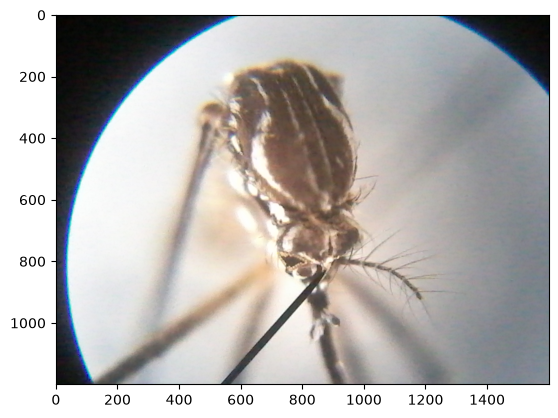

In [4]:
ruta_aegypti = data_path + 'Aedes aegypti/' + os.listdir(data_path + 'Aedes aegypti')[0]
imagen_aegypti = imread(ruta_aegypti)
plt.imshow(imagen_aegypti)


In [5]:
imagen_aegypti.shape


(1200, 1600, 3)

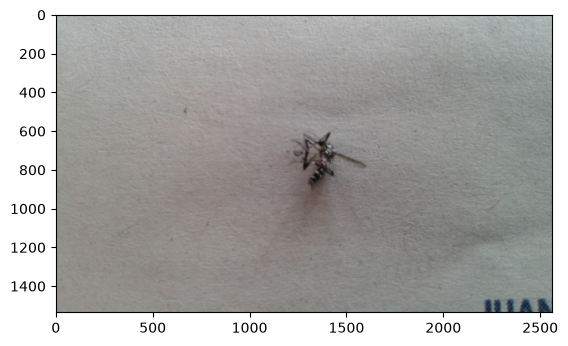

In [6]:
# 2. Visualizamos Aedes albopictus
ruta_albopictus = data_path + 'Aedes albopictus/' + os.listdir(data_path + 'Aedes albopictus')[0]
imagen_albopictus = imread(ruta_albopictus)
plt.imshow(imagen_albopictus)


In [7]:
imagen_albopictus.shape


(1536, 2560, 3)

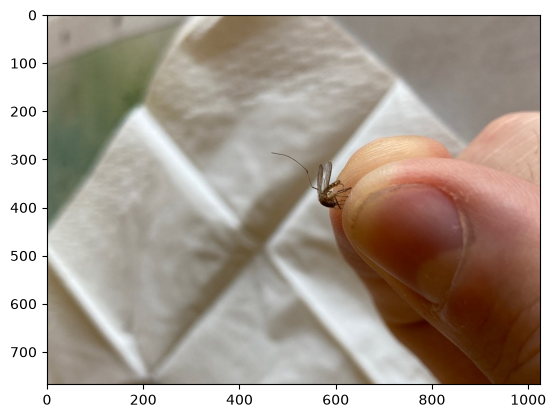

In [8]:
# 3. Visualizamos Culex
ruta_culex = data_path + 'Culex/' + os.listdir(data_path + 'Culex')[0]
imagen_culex = imread(ruta_culex)
plt.imshow(imagen_culex)


In [9]:
imagen_culex.shape


(768, 1024, 3)

**¿Cuántas imágenes tenemos en cada carpeta?**


In [10]:
len(os.listdir(data_path + 'Aedes aegypti'))


1413

In [11]:
len(os.listdir(data_path + 'Aedes albopictus'))


1801

In [12]:
len(os.listdir(data_path + 'Culex'))


1237

## 3.2 Dimensiones de las imágenes y tamaño de entrada


In [13]:
# Definimos el tamaño de entrada de 224x224 
image_shape = (224, 224, 3)
batch_size = 32


# 3.3 Manipulación de imágenes

Rotaciones y tratamientos de las imagenes para un mejor entrenamiento y presición en el resultado


In [14]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator


In [15]:
help(ImageDataGenerator)


Help on class ImageDataGenerator in module keras.src.legacy.preprocessing.image:

class ImageDataGenerator(builtins.object)
 |  ImageDataGenerator(
 |      featurewise_center=False,
 |      samplewise_center=False,
 |      featurewise_std_normalization=False,
 |      samplewise_std_normalization=False,
 |      zca_whitening=False,
 |      zca_epsilon=1e-06,
 |      rotation_range=0,
 |      width_shift_range=0.0,
 |      height_shift_range=0.0,
 |      brightness_range=None,
 |      shear_range=0.0,
 |      zoom_range=0.0,
 |      channel_shift_range=0.0,
 |      fill_mode='nearest',
 |      cval=0.0,
 |      horizontal_flip=False,
 |      vertical_flip=False,
 |      rescale=None,
 |      preprocessing_function=None,
 |      data_format=None,
 |      validation_split=0.0,
 |      interpolation_order=1,
 |      dtype=None
 |  )
 |
 |  DEPRECATED.
 |
 |  Methods defined here:
 |
 |  __init__(
 |      self,
 |      featurewise_center=False,
 |      samplewise_center=False,
 |      featur

In [16]:
image_gen = ImageDataGenerator(rotation_range=20, # rotación máxima de 20º
                               width_shift_range=0.15, # Desplazamiento en la anchura máximo del 15%
                               height_shift_range=0.15, # Desplazamiento en la altura máximo del 15%
                               rescale=1/255, # Reescalar la imagen para normalizarla entre 0-1
                               shear_range=0.15, # Distorsión de perspectiva
                               zoom_range=0.35, # Zoom pronunciado para compensar fotos con mosquito lejano
                               horizontal_flip=True, # Permitir giro horizontal (espejo)
                               fill_mode='nearest', # Rellenar píxeles vacíos con el más cercano
                               validation_split=0.20 # 20% para validación/test
                              )


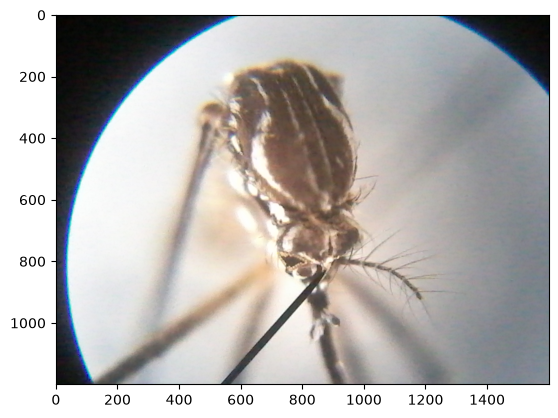

In [17]:
plt.imshow(imagen_aegypti)


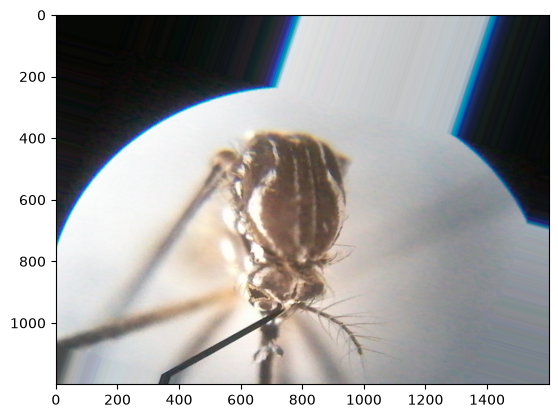

In [18]:
plt.imshow(image_gen.random_transform(imagen_aegypti))


In [19]:
# Generador de entrenamiento (80%)
train_image_gen = image_gen.flow_from_directory(data_path,
                                               target_size=image_shape[:2],
                                               color_mode='rgb',
                                               batch_size=batch_size,
                                               class_mode='categorical',
                                               subset='training',
                                               shuffle=True,
                                               seed=42)


Found 3562 images belonging to 3 classes.


In [20]:
# Generador de prueba / validación (20% restante)
test_datagen = ImageDataGenerator(rescale=1/255, validation_split=0.20)

test_image_gen = test_datagen.flow_from_directory(data_path,
                                                 target_size=image_shape[:2],
                                                 color_mode='rgb',
                                                 batch_size=batch_size,
                                                 class_mode='categorical',
                                                 subset='validation',
                                                 shuffle=False)


Found 889 images belonging to 3 classes.


In [21]:
train_image_gen.class_indices


{'Aedes aegypti': 0, 'Aedes albopictus': 1, 'Culex': 2}

### Cálculo de pesos de clase (Class Weights)
Dado que Culex tiene menor cantidad de imágenes que las especies de Aedes, calculamos pesos de clase para compensar el desbalance durante el entrenamiento.


In [22]:
from sklearn.utils.class_weight import compute_class_weight

clases_train = train_image_gen.classes
pesos = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(clases_train),
    y=clases_train
)
class_weights = dict(enumerate(pesos))
class_weights


{0: np.float64(1.049808429118774),
 1: np.float64(0.8239648392320148),
 2: np.float64(1.1993265993265994)}

# 4.Creación del Modelo
Implementamos la CNN propia basada en las especificaciones del proyecto:
`Conv2D(32) -> MaxPool -> Conv2D(64) -> MaxPool -> Conv2D(128) -> MaxPool -> Conv2D(256) -> MaxPool -> GlobalAvgPool -> Dense(128) -> Dropout(0.4) -> Softmax(3)`

In [23]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, BatchNormalization, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.optimizers import Adam

model = Sequential()

# BLOQUE CONVOLUCIONAL 1
model.add(Conv2D(filters=32, kernel_size=(3,3), input_shape=image_shape, activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))

# BLOQUE CONVOLUCIONAL 2
model.add(Conv2D(filters=64, kernel_size=(3,3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))

# BLOQUE CONVOLUCIONAL 3
model.add(Conv2D(filters=128, kernel_size=(3,3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))

# BLOQUE CONVOLUCIONAL 4 (Para capturar patrones morfológicos a 224x224)
model.add(Conv2D(filters=256, kernel_size=(3,3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))

# POOLING GLOBAL (Recomendado en la guía del proyecto en lugar de Flatten para evitar sobreajuste)
model.add(GlobalAveragePooling2D())

# CAPA DENSE INTERMEDIA
model.add(Dense(128, activation='relu'))

# CAPA DROPOUT
model.add(Dropout(0.4))

# CAPA FINAL DE CLASIFICACIÓN (3 clases = 3 neuronas con softmax)
model.add(Dense(3, activation='softmax'))

# Optimizador con tasa de aprendizaje ajustada para convergencia suave
model.compile(loss='categorical_crossentropy',
              optimizer=Adam(learning_rate=0.0003),
              metrics=['accuracy'])


In [24]:
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,619 (1.62 MB)

 Trainable params: 422,659 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

# 5.Entrenamiento del modelo


In [25]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
epochs = 35

In [26]:
results = model.fit(train_image_gen,
                    epochs=epochs,
                    validation_data=test_image_gen,
                    callbacks=[early_stop],
                    class_weight=class_weights)


Epoch 1/35
112/112 ━━━━━━━━━━━━━━━━━━━━ 219s 2s/step - accuracy: 0.5612 - loss: 0.8631 - val_accuracy: 0.2778 - val_loss: 1.3623
Epoch 2/35
112/112 ━━━━━━━━━━━━━━━━━━━━ 221s 2s/step - accuracy: 0.6025 - loss: 0.7399 - val_accuracy: 0.2778 - val_loss: 1.9100
Epoch 3/35
112/112 ━━━━━━━━━━━━━━━━━━━━ 240s 2s/step - accuracy: 0.6286 - loss: 0.6773 - val_accuracy: 0.2891 - val_loss: 1.7386
Epoch 4/35
112/112 ━━━━━━━━━━━━━━━━━━━━ 252s 2s/step - accuracy: 0.6373 - loss: 0.6694 - val_accuracy: 0.3813 - val_loss: 1.3168
Epoch 5/35
112/112 ━━━━━━━━━━━━━━━━━━━━ 251s 2s/step - accuracy: 0.6454 - loss: 0.6501 - val_accuracy: 0.5118 - val_loss: 0.9965
Epoch 6/35
112/112 ━━━━━━━━━━━━━━━━━━━━ 252s 2s/step - accuracy: 0.6614 - loss: 0.6475 - val_accuracy: 0.6828 - val_loss: 0.7107
Epoch 7/35
112/112 ━━━━━━━━━━━━━━━━━━━━ 252s 2s/step - accuracy: 0.6597 - loss: 0.6314 - val_accuracy: 0.6547 - val_loss: 0.7618
Epoch 8/35
112/112 ━━━━━━━━━━━━━━━━━━━━ 251s 2s/step - accuracy: 0.6931 - loss: 0.6088 - val_accu

In [27]:
import os
os.makedirs('../models', exist_ok=True)
model.save('../models/cnn_propia_mosquitos.h5')
print("Modelo guardado exitosamente en ../models/cnn_propia_mosquitos.h5")


Modelo guardado exitosamente en ../models/cnn_propia_mosquitos.h5


In [28]:
losses = pd.DataFrame(model.history.history)


<Axes: >

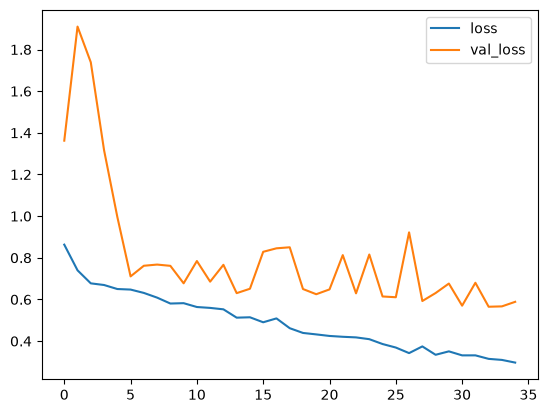

In [29]:
losses[['loss','val_loss']].plot()


<Axes: >

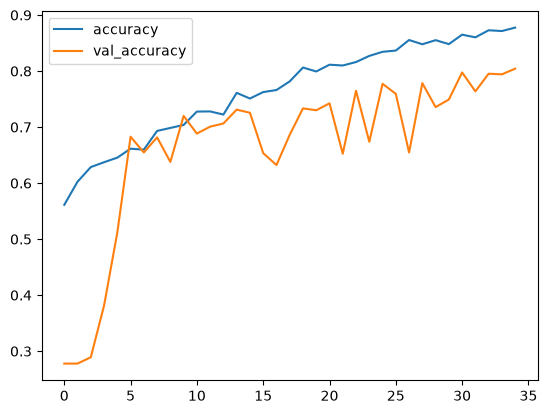

In [30]:
losses[['accuracy','val_accuracy']].plot()


# 6. Evaluación del modelo


## 6.1 Predicción sobre el conjunto de Test


In [31]:
model.metrics_names


['loss', 'compile_metrics']

In [32]:
model.evaluate(test_image_gen)


28/28 ━━━━━━━━━━━━━━━━━━━━ 22s 753ms/step - accuracy: 0.7953 - loss: 0.5650


[0.5650092959403992, 0.7952755689620972]

In [33]:
pred_probabilities = model.predict(test_image_gen)


28/28 ━━━━━━━━━━━━━━━━━━━━ 22s 771ms/step


In [34]:
test_image_gen.classes


array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

In [35]:
predictions = np.argmax(pred_probabilities, axis=-1)
predictions


array([1, 1, 1, 2, 1, 1, 2, 1, 2, 1, 1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 2,
       1, 1, 1, 1, 2, 2, 1, 1, 1, 2, 2, 1, 1, 0, 2, 1, 1, 2, 1, 1, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 1, 1, 1,

In [36]:
from sklearn.metrics import classification_report, confusion_matrix


In [37]:
print(classification_report(test_image_gen.classes, predictions, target_names=list(test_image_gen.class_indices.keys())))


                  precision    recall  f1-score   support

   Aedes aegypti       0.88      0.84      0.86       282
Aedes albopictus       0.77      0.81      0.79       360
           Culex       0.74      0.72      0.73       247

        accuracy                           0.80       889
       macro avg       0.80      0.79      0.79       889
    weighted avg       0.80      0.80      0.80       889



In [38]:
confusion_matrix(test_image_gen.classes, predictions)


array([[237,  33,  12],
       [ 18, 292,  50],
       [ 15,  54, 178]])

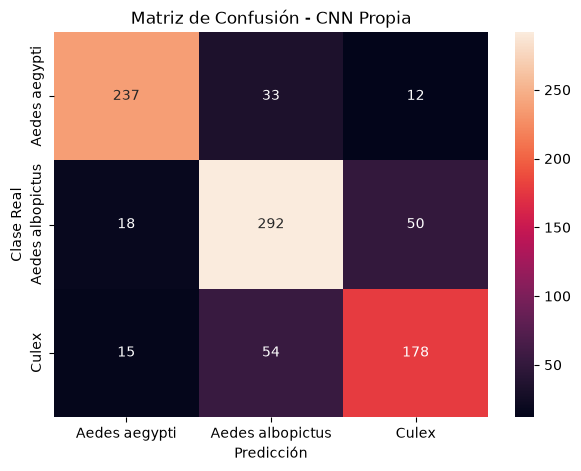

In [39]:
plt.figure(figsize=(7, 5))
sns.heatmap(confusion_matrix(test_image_gen.classes, predictions), annot=True, fmt='d',
            xticklabels=list(test_image_gen.class_indices.keys()),
            yticklabels=list(test_image_gen.class_indices.keys()))
plt.xlabel('Predicción')
plt.ylabel('Clase Real')
plt.title('Matriz de Confusión - CNN Propia')
plt.show()


## 6.2 Comparación con MobileNetV2 (Transfer Learning)
Siguiendo los requerimientos del proyecto, comparamos nuestra CNN propia contra un modelo preentrenado (MobileNetV2) usando Transfer Learning.


In [40]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D
from tensorflow.keras.models import Model

base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=image_shape)
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
output = Dense(3, activation='softmax')(x)

model_mobilenet = Model(inputs=base_model.input, outputs=output)

model_mobilenet.compile(loss='categorical_crossentropy',
                        optimizer='adam',
                        metrics=['accuracy'])

model_mobilenet.summary()


Model: "functional_16"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [41]:
results_mobilenet = model_mobilenet.fit(train_image_gen,
                                      epochs=10,
                                      validation_data=test_image_gen,
                                      callbacks=[early_stop],
                                      class_weight=class_weights)

model_mobilenet.save('../models/cnn_mobilenetv2_mosquitos.h5')


Epoch 1/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 169s 1s/step - accuracy: 0.6715 - loss: 0.6926 - val_accuracy: 0.7210 - val_loss: 0.6426
Epoch 2/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 167s 1s/step - accuracy: 0.7459 - loss: 0.5418 - val_accuracy: 0.7705 - val_loss: 0.5635
Epoch 3/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 166s 1s/step - accuracy: 0.7732 - loss: 0.4882 - val_accuracy: 0.7604 - val_loss: 0.5540
Epoch 4/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 169s 2s/step - accuracy: 0.7838 - loss: 0.4712 - val_accuracy: 0.7458 - val_loss: 0.5813
Epoch 5/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 167s 1s/step - accuracy: 0.7959 - loss: 0.4416 - val_accuracy: 0.7762 - val_loss: 0.5561
Epoch 6/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 169s 2s/step - accuracy: 0.8043 - loss: 0.4301 - val_accuracy: 0.7852 - val_loss: 0.5674
Epoch 7/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 167s 1s/step - accuracy: 0.8040 - loss: 0.4309 - val_accuracy: 0.8043 - val_loss: 0.5525
Epoch 8/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 167s 1s/step - accuracy: 0.8139 - loss: 0.3971 - val_accu

In [42]:
pred_mobilenet = np.argmax(model_mobilenet.predict(test_image_gen), axis=-1)
print(classification_report(test_image_gen.classes, pred_mobilenet, target_names=list(test_image_gen.class_indices.keys())))


28/28 ━━━━━━━━━━━━━━━━━━━━ 24s 801ms/step
                  precision    recall  f1-score   support

   Aedes aegypti       0.99      0.81      0.89       282
Aedes albopictus       0.71      0.85      0.77       360
           Culex       0.74      0.69      0.71       247

        accuracy                           0.79       889
       macro avg       0.81      0.78      0.79       889
    weighted avg       0.81      0.79      0.79       889



## 6.3 Predicción para una nueva imagen


In [43]:
ruta_nueva_imagen = data_path + 'Aedes aegypti/' + os.listdir(data_path + 'Aedes aegypti')[10]


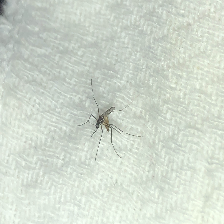

In [44]:
from tensorflow.keras.preprocessing import image

nueva_imagen = image.load_img(ruta_nueva_imagen, target_size=image_shape[:2])
nueva_imagen


In [45]:
type(nueva_imagen)


PIL.Image.Image

In [46]:
nueva_imagen = image.img_to_array(nueva_imagen)


In [47]:
nueva_imagen.shape


(224, 224, 3)

In [48]:
nueva_imagen = np.expand_dims(nueva_imagen, axis=0) / 255.0
nueva_imagen.shape


(1, 224, 224, 3)

In [49]:
model.predict(nueva_imagen)


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


array([[0.0494201 , 0.847822  , 0.10275787]], dtype=float32)

In [50]:
test_image_gen.class_indices


{'Aedes aegypti': 0, 'Aedes albopictus': 1, 'Culex': 2}